Flory huugins potential

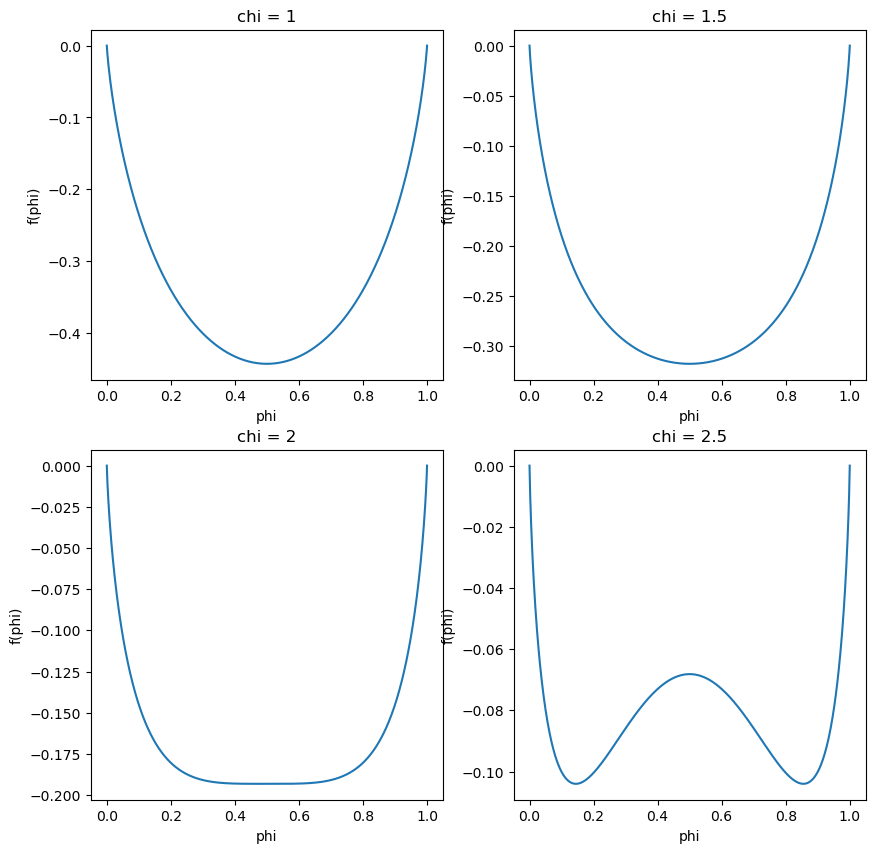

In [28]:
import numpy as np
import matplotlib.pyplot as plt
delta = 1e-6
phi = np.linspace(delta,1-delta,1000)
chis = [1,1.5,2,2.5]

fig, axes = plt.subplots(2,2, figsize=(10,10))
plt.subplots_adjust(wspace=0.2, hspace=0.2)

for i, chi in enumerate(chis):
    f_phi = phi * np.log(phi) + (1 - phi) * np.log(1-phi) + chi * phi * (1-phi)

    ax = axes.flatten()[i]
    ax.plot(phi, f_phi)
    ax.set_xlabel("phi")
    ax.set_ylabel("f(phi)")
    ax.set_title(f"chi = {chi}")
plt.show()

spinodal
Binodal - by symmetry we will have f'(phi_a) = f'(phi_b) = 0

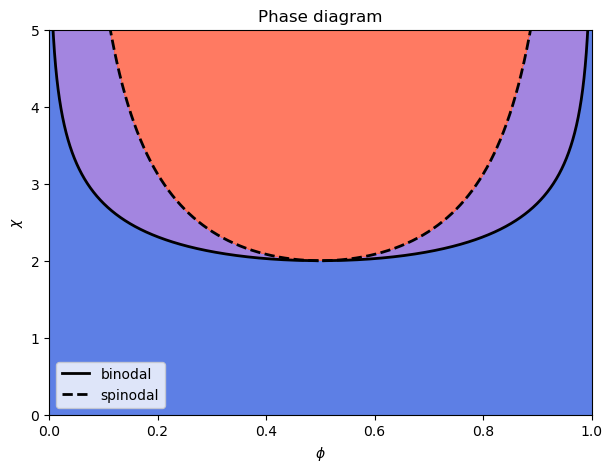

In [ ]:
from scipy.optimize import brentq

phi = np.linspace(delta, 1-delta, 1000)
chi = np.linspace(0, 5, 5000)
PHI, CHI = np.meshgrid(phi, chi)

# binodal branch for chi > 2
chi_b = np.linspace(2.0001, 5, 1200)

# spinodal branches for symmetric Flory-Huggins
phi_s_left = 0.5 * (1 - np.sqrt(1 - 2 / chi_b))
phi_s_right = 0.5 * (1 + np.sqrt(1 - 2 / chi_b))

def binodal_left(chi_val):
    def g(p):
        return np.log(p / (1 - p)) + chi_val * (1 - 2 * p)
    return brentq(g, delta, 0.5 - delta)

phi_b_left = np.array([binodal_left(c) for c in chi_b])
phi_b_right = 1 - phi_b_left

# interpolate branches onto the grid
pbL = np.interp(CHI[:, 0], chi_b, phi_s_left)[:, None]
pbR = np.interp(CHI[:, 0], chi_b, phi_s_right)[:, None]
psL = np.interp(CHI[:, 0], chi_b, phi_b_left)[:, None]
psR = np.interp(CHI[:, 0], chi_b, phi_b_right)[:, None]

# 0 = stable, 1 = metastable, 2 = unstable
region = np.zeros_like(PHI, dtype=int)

two_phase = CHI >= 2

# unstable: inside spinodal
region[two_phase & (PHI >= psL) & (PHI <= psR)] = 2

# metastable: between binodal and spinodal
region[two_phase & (((PHI >= pbL) & (PHI < psL)) |
                    ((PHI > psR) & (PHI <= pbR)))] = 1
plt.figure(figsize=(7, 5))
plt.contourf(
    PHI, CHI, region,
    levels=[-0.5, 0.5, 1.5, 2.5],
    colors=["royalblue", "mediumpurple", "tomato"],
    alpha=0.85
)

# binodal curves
plt.plot(phi_b_left, chi_b, "k-", lw=2, label="binodal")
plt.plot(phi_b_right, chi_b, "k-", lw=2)
# spinodal curves
plt.plot(phi_s_left, chi_b, "k--", lw=2, label="spinodal")
plt.plot(phi_s_right, chi_b, "k--", lw=2)
plt.xlim(0, 1)
plt.ylim(0, 5)
plt.xlabel(r"$\phi$")
plt.ylabel(r"$\chi$")
plt.title("Phase diagram")
plt.legend()
plt.show()


In [36]:
def f(phi, chi):
    F = phi * np.log(phi) + (1 - phi) * np.log(1 - phi) + chi * phi * (1-phi)
    return F

def df(phi, chi):
    dF = np.log(phi) - np.log(1-phi) + chi * (1 - 2 * phi)
    return dF




